# Harmonic offset: estimating and removing the IRF-decay timing offset

This example walks through:
- Simulating a two-well plate (one mono-exponential, one bi-exponential well) with a known offset that grows across the field
- What the offset does to standard phasors and phase lifetimes
- Estimating the offset map with `HarmonicOffset`: the per-harmonic mono estimate, the chi-square test that keeps only mono-exponential pixels, and the spatial surface
- The bracket that holds for every pixel, mono or not

<small>Author - Vikas</small>

In [ ]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "ex_helper")

from sim_general_image import ROIMaskGenerator, WellPlateShape

from pyfli.data_vnp import ColorProcessor, DataViewer
from pyfli.io import DataOperations
from pyfli.laguerre import LaguerreFLI
from pyfli.phasor.harmonic_offset import HarmonicOffset, correct_phasors, t0_from_h_shift
from pyfli.phasor.phasorS import PhasorAnalyzer
from pyfli.reconstruction import ParamToDecay
from pyfli.reconstruction.common_reconstruct import gate_starts

In [ ]:
# Path to the local IRF file
IRF_PATH = "<select file/folder path>"

In [ ]:
rng = np.random.default_rng()

LASER_HZ = 80e6
PERIOD_NS = 1e9 / LASER_HZ

irf = np.clip(np.asarray(DataOperations(irf_path=IRF_PATH).load_irf(), dtype=float)[120, 40, :], 0.0, None)
irf /= irf.sum()
N_BINS = irf.size
DT = PERIOD_NS / N_BINS
t = gate_starts(PERIOD_NS, N_BINS)
print(f"{N_BINS} bins of {DT * 1e3:.1f} ps over {PERIOD_NS} ns")

INFO:pyfli:Initiating IRF load from: <select file/folder path>


256 bins of 48.8 ps over 12.5 ns


## A two-well plate with a known offset

- **Well 1** is mono-exponential (`tau` about 2.0 ns); **well 2** is bi-exponential (`tau1` about 0.5 ns, `tau2` about 2.5 ns, `alpha1` about 0.4).
- The decay of each pixel is delayed against the IRF by `h(r) = 0.20 + 0.25 x` ns, `x` running from 0 to 1 across the field: a constant offset (the IRF was recorded separately) plus a linear skew.
- The data are the exact expectation of PyFLI's periodic forward model (`ParamToDecay(..., shift_method="circular")`, the same model the solver fits) with Poisson noise, about 2e4 photons per pixel and a background of 0.5 counts per bin. `h` is the solver's `h_shift`; the harmonic offset reported in the phasor frame is `t0 = h - dt/2` (`t0_from_h_shift`), because the forward model excites at the start of each IRF bin.

In [ ]:
generator = ROIMaskGenerator((64, 128), top=5, bottom=5, left=5, right=5)
two_wells = WellPlateShape(rows=1, cols=2, gap=0.15)
img_cluster = generator.generate_cluster_mask(two_wells)
mask = generator.generate_binary_mask(two_wells).astype(bool)
H, W = mask.shape
mono_well, bi_well = img_cluster == 1, img_cluster == 2
well_names = {1: "well 1 (mono)", 2: "well 2 (bi)"}

x = np.broadcast_to(np.linspace(0.0, 1.0, W), (H, W))
h_true = 0.20 + 0.25 * x

tau1 = np.where(mono_well, rng.uniform(1.9, 2.1, (H, W)), rng.uniform(0.45, 0.55, (H, W)))
tau2 = np.where(mono_well, tau1, rng.uniform(2.4, 2.6, (H, W)))
alpha1 = np.where(mono_well, 1.0, rng.uniform(0.35, 0.45, (H, W)))
truth = {
    "tau1_map": tau1,
    "tau2_map": tau2,
    "alpha1_map": alpha1,
    "photon_count_map": np.where(mask, rng.uniform(1.5e4, 2.5e4, (H, W)), 0.0),
    "v_shift_map": np.where(mask, 0.5, 0.0),
    "h_shift_map": h_true,
}
tau_mean_true = alpha1 * tau1 + (1 - alpha1) * tau2

expected = ParamToDecay("bi-exponential", LASER_HZ / 1e6, irf, shift_method="circular").reconstruct_vectorized(truth)
decay = rng.poisson(np.where(mask[..., None], expected["fit_map"], 0.0)).astype(float)
print(f"decay cube {decay.shape}, median photons per pixel {np.median(decay.sum(-1)[mask]):.0f}")

Reconstructing decay (vectorized)...


decay cube (64, 128, 256), median photons per pixel 20190


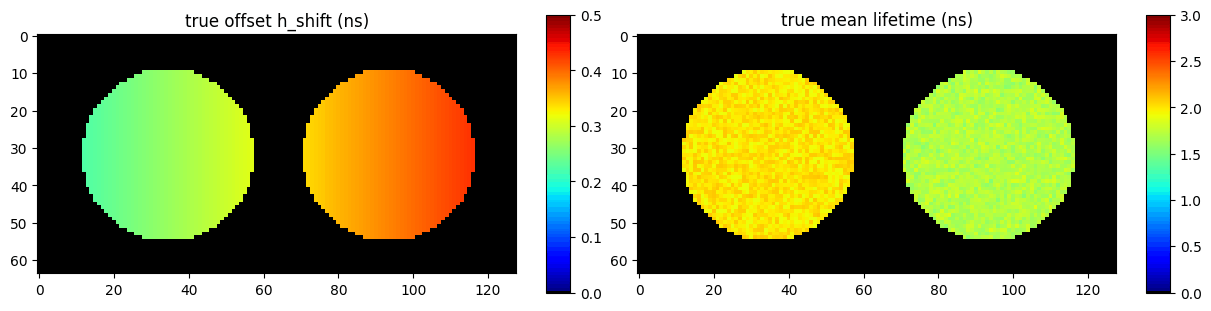

In [ ]:
jet_m = ColorProcessor().lowest_zero("jet")
_ = DataViewer().display_data(
    [np.where(mask, h_true, 0), np.where(mask, tau_mean_true, 0)],
    structure=(1, 2),
    coord=None,
    data_names=["true offset h_shift (ns)", "true mean lifetime (ns)"],
    cmaps=[jet_m] * 2,
    v_ranges=[(0, 0.5), (0, 3)],
    figsize=(12, 3),
    normalize=False,
    yscale="linear",
)

## Standard phasor analysis: the offset rotates every phasor

The phasors are calibrated with the IRF as usual (`PhasorAnalyzer.calibrate`). The offset is not part of the IRF, so it stays in the calibrated phasor as a rotation by `k omega t0`. The mono-exponential well is pushed off the universal semicircle, and its phase lifetime is too long. The modulation `|z_k|` does not change under a rotation, so the modulation lifetime is unaffected: the disagreement between phase and modulation lifetimes of a mono-exponential sample is the signature of an offset.

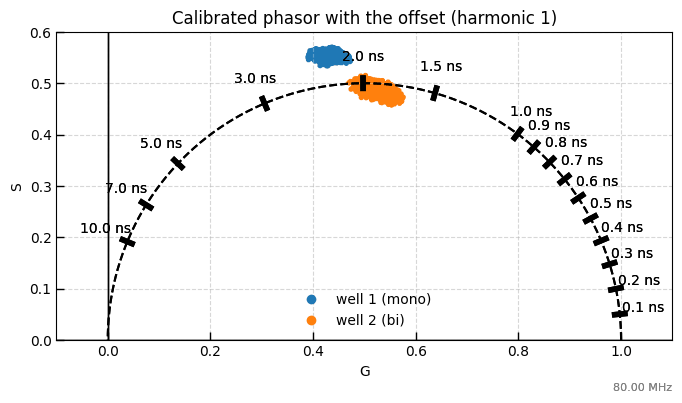

In [ ]:
analyzer = PhasorAnalyzer(frequency_hz=LASER_HZ, time_axis_ns=t, n_harmonics=3)
G, S = analyzer.create_phasor_cpu(decay)
Gc, Sc = analyzer.calibrate(G, S, irf)

BLUE, ORANGE = (0.12, 0.47, 0.71), (1.0, 0.5, 0.05)


def solid(color):
    return np.broadcast_to(np.asarray(color), (*mask.shape, 3))


def phasor_plot(g, s, title):
    fig, ax = plt.subplots(figsize=(8, 4))
    analyzer.plot_phasor_diagram(g, s, mask=mono_well, colors=solid(BLUE), ax=ax)
    analyzer.plot_phasor_diagram(g, s, mask=bi_well, colors=solid(ORANGE), ax=ax, title=title)
    ax.legend(
        handles=[plt.Line2D([], [], marker="o", linestyle="", color=c, label=n) for c, n in [(BLUE, well_names[1]), (ORANGE, well_names[2])]],
        frameon=False, loc="lower center",
    )
    plt.show()


phasor_plot(Gc[0], Sc[0], "Calibrated phasor with the offset (harmonic 1)")

## Estimating the offset from the harmonics

In [ ]:
result = HarmonicOffset(analyzer).estimate(decay, irf, order=1, v_shift=truth["v_shift_map"])
h_est = result["h_shift_map"]
error_ps = 1e3 * (h_est - h_true)

pd.DataFrame(
    [
        {
            "well": well_names[cid],
            "accepted as mono-exponential (%)": 100 * result["accepted"][img_cluster == cid].mean(),
            "median h_shift error (ps)": np.median(error_ps[img_cluster == cid]),
            "h_shift error p5 - p95 (ps)": np.ptp(np.percentile(error_ps[img_cluster == cid], [5, 95])),
        }
        for cid in well_names
    ]
).set_index("well").round(2)

,accepted as mono-exponential (%),median h_shift error (ps),h_shift error p5 - p95 (ps)
well,,,
well 1 (mono),94.97,-0.16,1.56
well 2 (bi),0.00,2.23,1.56


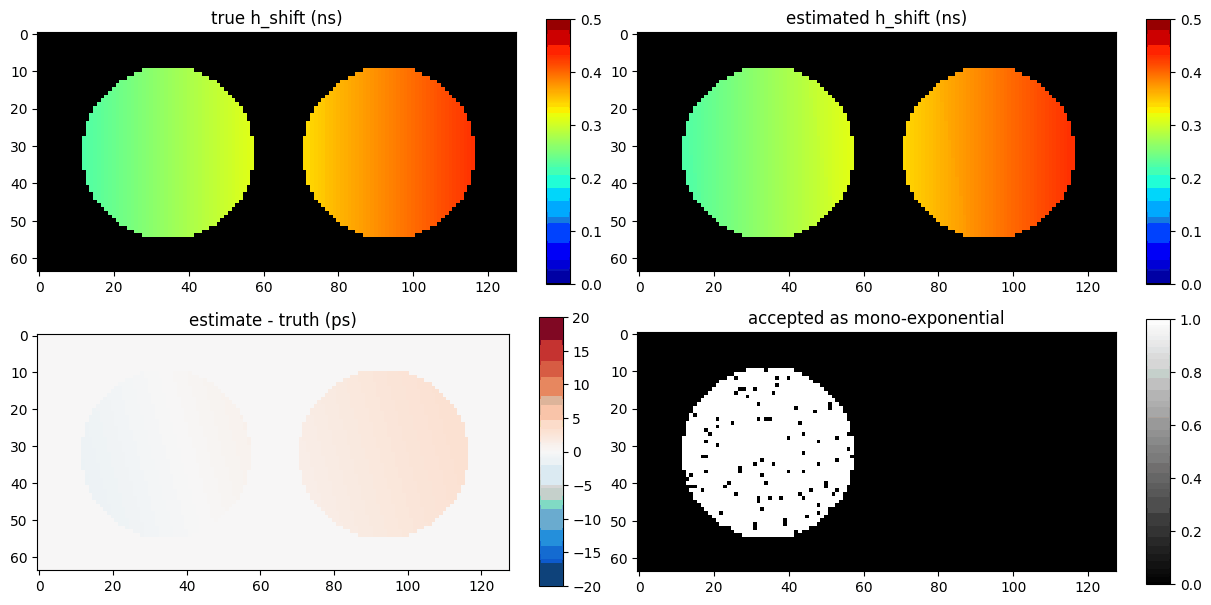

In [ ]:
_ = DataViewer().display_data(
    [np.where(mask, h_true, 0), np.where(mask, h_est, 0), np.where(mask, error_ps, 0), np.where(mask, result["accepted"], 0)],
    structure=(2, 2),
    coord=None,
    data_names=["true h_shift (ns)", "estimated h_shift (ns)", "estimate - truth (ps)", "accepted as mono-exponential"],
    cmaps=[jet_m, jet_m, "RdBu_r", "gray"],
    v_ranges=[(0, 0.5), (0, 0.5), (-20, 20), (0, 1)],
    figsize=(12, 6),
    normalize=False,
    yscale="linear",
)

### A bracket that holds for every pixel

bi-exponential pixels whose true offset lies inside the bracket: 100.0 %


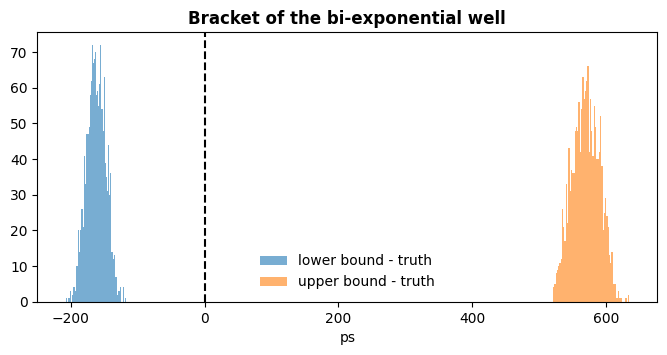

In [ ]:
lower = result["lower"] - t0_from_h_shift(h_true, t)
upper = result["upper"] - t0_from_h_shift(h_true, t)
inside = (lower <= 0) & (upper >= 0)
print(f"bi-exponential pixels whose true offset lies inside the bracket: {100 * inside[bi_well].mean():.1f} %")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(1e3 * lower[bi_well], bins=60, alpha=0.6, label="lower bound - truth")
ax.hist(1e3 * upper[bi_well], bins=60, alpha=0.6, label="upper bound - truth")
ax.axvline(0, color="k", linestyle="--")
ax.set_xlabel("ps")
ax.set_title("Bracket of the bi-exponential well", fontweight="bold")
ax.legend(frameon=False)
plt.show()

## Correcting the phasors

The correction `z_k -> exp(-i k omega t0) z_k` (`correct_phasors`) is exact for every decay, mono or not. After it, the mono-exponential well is back on the semicircle and its phase and modulation lifetimes agree with the truth; the bi-exponential well moves inside the circle where it belongs.

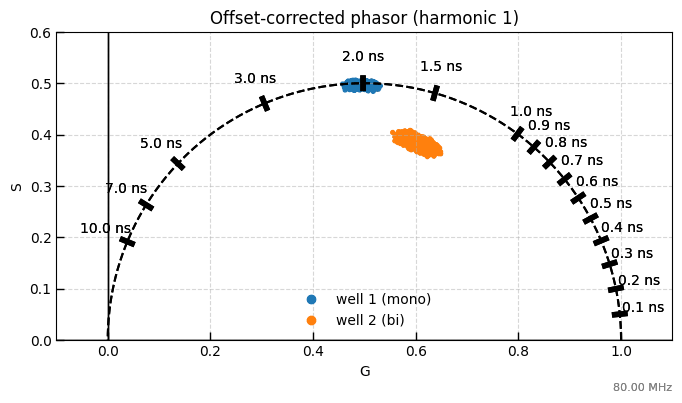

,mono well true tau,mono well phase tau,mono well modulation tau
phasor,,,
before,1.998,2.557,2.022
after correction,1.998,1.998,2.022


In [ ]:
Gk, Sk = correct_phasors(Gc, Sc, result["t0_map"], LASER_HZ)
phasor_plot(Gk[0], Sk[0], "Offset-corrected phasor (harmonic 1)")

rows = []
for name, (g, s) in {"before": (Gc[0], Sc[0]), "after correction": (Gk[0], Sk[0])}.items():
    tau_phi = analyzer.compute_lifetime(g, s)
    tau_m = analyzer.compute_modulation_lifetime(g, s)
    rows.append(
        {
            "phasor": name,
            "mono well true tau": np.median(tau1[mono_well]),
            "mono well phase tau": np.nanmedian(tau_phi[mono_well]),
            "mono well modulation tau": np.nanmedian(tau_m[mono_well]),
        }
    )
pd.DataFrame(rows).set_index("phasor").round(3)